# EDA — dataset de eritrocitos infectados con malaria

Issue: https://github.com/Jacogz/DL-QPI/issues/2

Dataset: [P. Vivax (Malaria) Infected Human Blood Smears](https://www.kaggle.com/datasets/orvile/p-vivax-malaria-infected-human-blood-smears)

## 1. Preparación de datos

Configuración única por integrante, antes de correr esta sección:

1. Generar un token en https://www.kaggle.com/settings/api → **Generate New Token**. El token (empieza con `KGAT_`) se muestra una sola vez: cópialo.
2. Ejecutar las celdas de abajo. La celda de credenciales va a pedir que pegues ese token (queda solo en el runtime remoto de Colab, nunca en el repo).

El CLI de `kaggle` ya no usa `kaggle.json` con `username`+`key` (Basic Auth); usa este token único vía `~/.kaggle/access_token`. `files.upload()` tampoco funciona desde la extensión de Colab en VS Code (depende de la interfaz web de colab.research.google.com), por eso el token se pide con `getpass`.

In [1]:
!pip install -q -U kaggle kagglehub

In [3]:
import os
from getpass import getpass

import kagglehub


In [3]:
kaggle_token = getpass("Kaggle API token (KGAT_...): ")

kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)
token_path = os.path.join(kaggle_dir, "access_token")
with open(token_path, "w") as f:
    f.write(kaggle_token.strip())
os.chmod(token_path, 0o600)

In [4]:
BASE_DIR = '/content/data'
os.environ['KAGGLEHUB_CACHE'] = BASE_DIR

dataset_path = kagglehub.dataset_download('orvile/p-vivax-malaria-infected-human-blood-smears')
print(f'Dataset descargado en: {dataset_path}')

Using Colab cache for faster access to the 'p-vivax-malaria-infected-human-blood-smears' dataset.
Dataset descargado en: /kaggle/input/p-vivax-malaria-infected-human-blood-smears


## 2. Estructura del dataset

In [5]:
import pathlib
from collections import Counter

root = pathlib.Path(dataset_path)
all_files = [f for f in root.rglob('*') if f.is_file()]
total_size = sum(f.stat().st_size for f in all_files)

print(f'Estructura de {dataset_path}:\n')

for sub in sorted(p for p in root.iterdir() if p.is_dir()):
    files = [f for f in sub.rglob('*') if f.is_file()]
    size = sum(f.stat().st_size for f in files)
    print(f'  {sub.name}/  -> {len(files)} archivos, {size / (1024 ** 2):.1f} MB')

root_files = [f for f in root.iterdir() if f.is_file()]
if root_files:
    size = sum(f.stat().st_size for f in root_files)
    print(f'  (raíz)  -> {len(root_files)} archivos, {size / (1024 ** 2):.1f} MB')

print(f'\nTotal: {len(all_files)} archivos, {total_size / (1024 ** 3):.2f} GB')

# Desglose por extensión: la cuenta por carpeta no distinguía las .json de
# anotaciones de las imágenes, así que quedaban "escondidas" dentro del total.
ext_counts = Counter(f.suffix.lower() for f in all_files)
print('\nPor extensión:')
for ext, count in sorted(ext_counts.items(), key=lambda kv: -kv[1]):
    print(f'  {ext or "(sin extensión)"}: {count}')

json_files = [f for f in all_files if f.suffix.lower() == '.json']
if json_files:
    print('\nArchivos .json (anotaciones):')
    for jf in json_files:
        print(f'  {jf.relative_to(root)}  ({jf.stat().st_size / 1024:.1f} KB)')

Estructura de /kaggle/input/p-vivax-malaria-infected-human-blood-smears:

  malaria/  -> 1330 archivos, 2162.2 MB

Total: 1330 archivos, 2.11 GB

Por extensión:
  .png: 1208
  .jpg: 120
  .json: 2

Archivos .json (anotaciones):
  malaria/test.json  (697.8 KB)
  malaria/training.json  (9346.3 KB)


## 3. Anotaciones (.json)

Cada `.json` agrupa las anotaciones (caja delimitadora + categoría) de los eritrocitos marcados en las imágenes. El formato no está documentado en la ficha de Kaggle, así que primero se inspecciona la estructura real de uno de los dos archivos antes de construir el DataFrame combinado.

In [6]:
import json

with open(json_files[0]) as f:
    raw = json.load(f)

print(f'Archivo: {json_files[0].name}')
print(f'Tipo del nivel superior: {type(raw).__name__}')

if isinstance(raw, dict):
    print(f'Claves de nivel superior ({len(raw)}): {list(raw.keys())[:10]}')
    first_key = next(iter(raw))
    print(f'\nEjemplo (clave "{first_key}"):')
    print(json.dumps(raw[first_key], indent=2, ensure_ascii=False)[:1500])
elif isinstance(raw, list):
    print(f'Elementos: {len(raw)}')
    print('\nEjemplo (primer elemento):')
    print(json.dumps(raw[0], indent=2, ensure_ascii=False)[:1500])

Archivo: test.json
Tipo del nivel superior: list
Elementos: 120

Ejemplo (primer elemento):
{
  "image": {
    "checksum": "eea3bfd6a929bcb06f9786667cd3fbb2",
    "pathname": "/images/41be1bd3-0d31-4881-bf1f-3ccdfa21ff12.jpg",
    "shape": {
      "r": 1383,
      "c": 1944,
      "channels": 3
    }
  },
  "objects": [
    {
      "bounding_box": {
        "minimum": {
          "r": 576,
          "c": 1744
        },
        "maximum": {
          "r": 708,
          "c": 1883
        }
      },
      "category": "red blood cell"
    },
    {
      "bounding_box": {
        "minimum": {
          "r": 863,
          "c": 1249
        },
        "maximum": {
          "r": 977,
          "c": 1373
        }
      },
      "category": "red blood cell"
    },
    {
      "bounding_box": {
        "minimum": {
          "r": 210,
          "c": 1573
        },
        "maximum": {
          "r": 335,
          "c": 1711
        }
      },
      "category": "red blood cell"
    },
    {


In [7]:
import pandas as pd

annotation_rows = []
for jf in json_files:
    with open(jf) as f:
        data = json.load(f)
    for entry in data:
        image_path = entry['image']['pathname']
        for obj in entry['objects']:
            annotation_rows.append({
                'split': jf.stem,
                'image': image_path,
                'category': obj['category'],
            })

annotations_df = pd.DataFrame(annotation_rows)

print(f'Anotaciones totales (eritrocitos marcados): {len(annotations_df)}')
print(f'Imágenes con al menos una anotación: {annotations_df["image"].nunique()}')

print('\nPor split:')
print(annotations_df['split'].value_counts())

print('\nCategorías encontradas:')
print(annotations_df['category'].value_counts())

# 'leukocyte' (glóbulo blanco) y 'difficult' (etiqueta ambigua, sin clasificar) no son
# eritrocitos infectados/sanos -- se excluyen del conteo de eritrocitos si aparecen.
NON_ERYTHROCYTE_CATEGORIES = {'leukocyte', 'difficult'}
HEALTHY_CATEGORY = 'red blood cell'

excluded_df = annotations_df[annotations_df['category'].isin(NON_ERYTHROCYTE_CATEGORIES)]
if len(excluded_df):
    print(f'\nExcluidas del conteo de eritrocitos (no son RBC o etiqueta ambigua): {len(excluded_df)}')
    print(excluded_df['category'].value_counts())

erythrocytes_df = annotations_df[~annotations_df['category'].isin(NON_ERYTHROCYTE_CATEGORIES)].copy()
erythrocytes_df['estado'] = erythrocytes_df['category'].apply(
    lambda c: 'sano' if c == HEALTHY_CATEGORY else 'enfermo'
)

print(f'\nEritrocitos totales: {len(erythrocytes_df)}')
print(erythrocytes_df['estado'].value_counts())
print(f"  ({erythrocytes_df['estado'].value_counts(normalize=True).mul(100).round(1).to_dict()} %)")

print('\nDistribución de eritrocitos enfermos por tipo:')
sick_df = erythrocytes_df[erythrocytes_df['estado'] == 'enfermo']
print(sick_df['category'].value_counts())

Anotaciones totales (eritrocitos marcados): 86035
Imágenes con al menos una anotación: 1328

Por split:
split
training    80113
test         5922
Name: count, dtype: int64

Categorías encontradas:
category
red blood cell    83034
trophozoite        1584
ring                522
difficult           446
schizont            190
gametocyte          156
leukocyte           103
Name: count, dtype: int64

Excluidas del conteo de eritrocitos (no son RBC o etiqueta ambigua): 549
category
difficult    446
leukocyte    103
Name: count, dtype: int64

Eritrocitos totales: 85486
estado
sano       83034
enfermo     2452
Name: count, dtype: int64
  ({'sano': 97.1, 'enfermo': 2.9} %)

Distribución de eritrocitos enfermos por tipo:
category
trophozoite    1584
ring            522
schizont        190
gametocyte      156
Name: count, dtype: int64


## 4. Descripción de las imágenes

In [8]:
import random

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}
image_files = sorted(f for f in all_files if f.suffix.lower() in IMAGE_EXTS)
print(f'Imágenes encontradas: {len(image_files)}')

Imágenes encontradas: 1328


In [9]:
# Tamaño/modo: lectura de cabecera (PIL no decodifica los píxeles hasta que se piden),
# barato incluso sobre todas las imágenes -- a diferencia del histograma de abajo, que
# sí carga los píxeles y por eso se hace sobre una muestra.
sizes = []
modes = []
for fp in image_files:
    with Image.open(fp) as img:
        sizes.append(img.size)
        modes.append(img.mode)

size_counts = Counter(sizes)
mode_counts = Counter(modes)

print(f'Dimensiones ({len(image_files)} imágenes):')
for size, count in size_counts.most_common():
    print(f'  {size[0]}x{size[1]} px: {count}')

print('\nModos de color (canales):')
for mode, count in mode_counts.most_common():
    print(f'  {mode}: {count}')

Dimensiones (1328 imágenes):
  1600x1200 px: 1208
  1944x1383 px: 120

Modos de color (canales):
  RGB: 1328


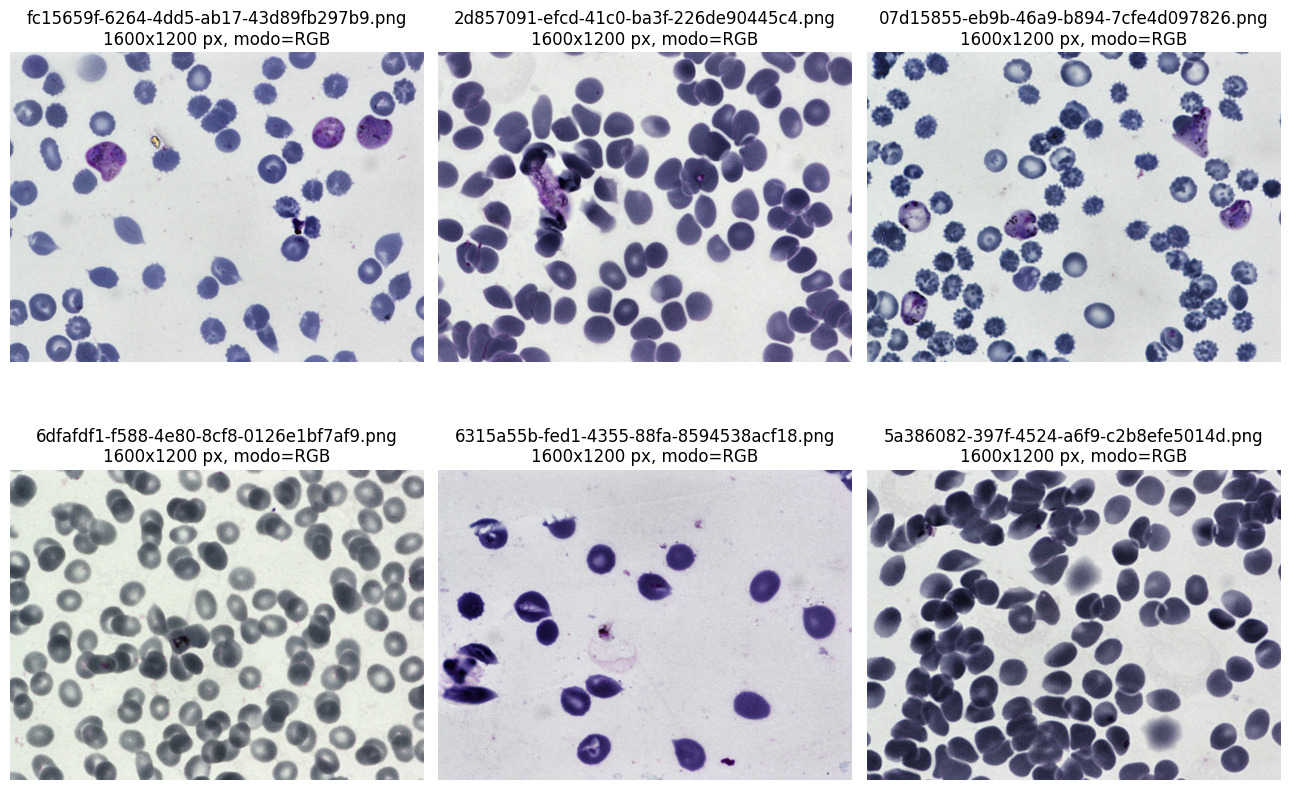

In [10]:
random.seed(42)
sample_files = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, fp in zip(axes.ravel(), sample_files):
    img = Image.open(fp)
    ax.imshow(img)
    ax.set_title(f'{fp.name}\n{img.size[0]}x{img.size[1]} px, modo={img.mode}')
    ax.axis('off')
plt.tight_layout()
plt.show()

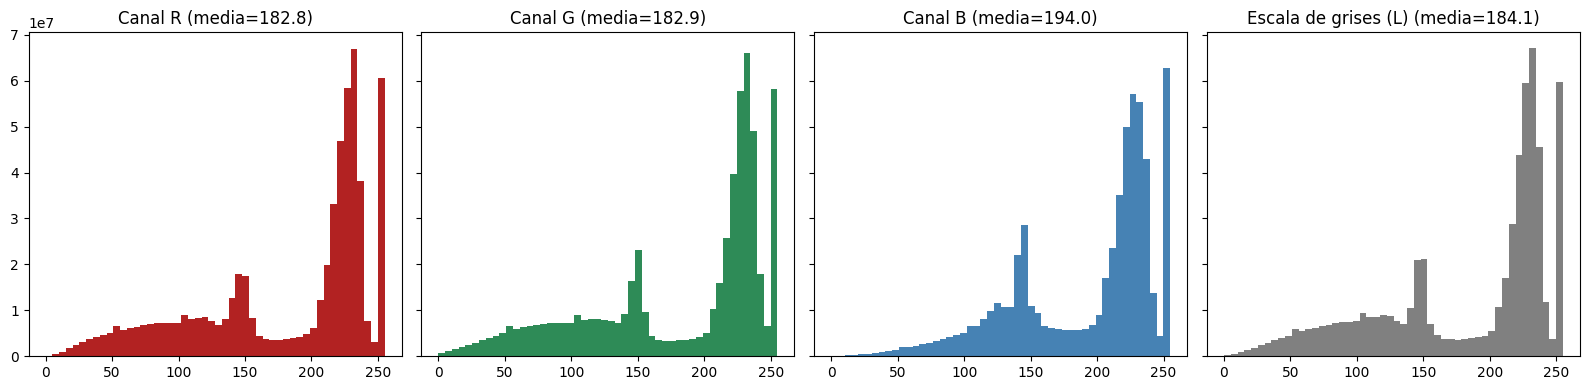

In [11]:
N_SAMPLE_IMG = min(300, len(image_files))
sample_for_hist = random.sample(image_files, N_SAMPLE_IMG)
main_mode = mode_counts.most_common(1)[0][0]

if main_mode == 'RGB':
    channel_values = {c: [] for c in 'RGB'}
    gray_values = []
    for fp in sample_for_hist:
        img = Image.open(fp)
        arr = np.array(img.convert('RGB'))
        for i, c in enumerate('RGB'):
            channel_values[c].append(arr[..., i].ravel())
        gray_values.append(np.array(img.convert('L'), dtype=np.uint8).ravel())

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
    colors = {'R': 'firebrick', 'G': 'seagreen', 'B': 'steelblue'}
    for ax, c in zip(axes[:3], 'RGB'):
        values = np.concatenate(channel_values[c])
        ax.hist(values, bins=50, color=colors[c])
        ax.set_title(f'Canal {c} (media={values.mean():.1f})')

    gray_values = np.concatenate(gray_values)
    axes[3].hist(gray_values, bins=50, color='gray')
    axes[3].set_title(f'Escala de grises (L) (media={gray_values.mean():.1f})')

    plt.tight_layout()
    plt.show()
else:
    values = np.concatenate([
        np.array(Image.open(fp).convert('L'), dtype=np.uint8).ravel() for fp in sample_for_hist
    ])
    plt.hist(values, bins=50, color='steelblue')
    plt.title(f'Distribución de valores de píxel (muestra de {N_SAMPLE_IMG}, media={values.mean():.1f})')
    plt.show()

## 5. Recorte en parches de 256x256

Se toma una imagen de muestra y se corta en parches no solapados de 256x256 px (se descarta el sobrante en los bordes si las dimensiones no son múltiplo exacto).

002f20ad-2ace-499c-9335-c9080bc3e6b5.png: 1600x1200 px -> 4x6 = 24 parches de 256x256
  (sobrante descartado: 176px alto, 64px ancho)


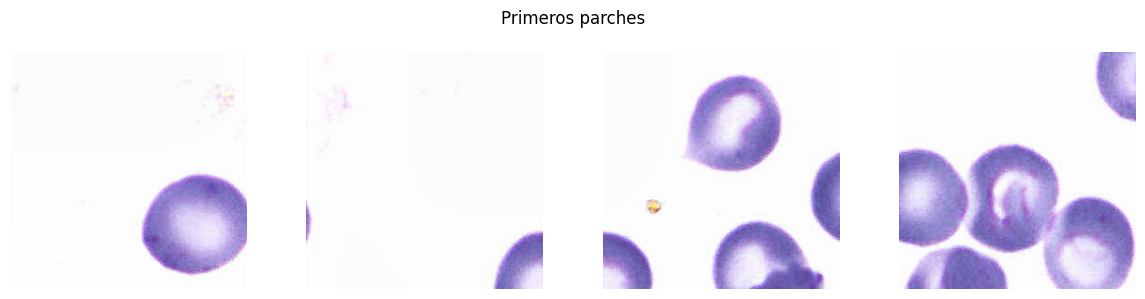


Las imágenes varían en tamaño (2 tamaños distintos); el número de parches por imagen depende de sus dimensiones individuales, no hay un total único.


In [12]:
PATCH_SIZE = 256

sample_img_path = image_files[0]
img_arr = np.array(Image.open(sample_img_path).convert(main_mode))

h, w = img_arr.shape[:2]
n_rows, n_cols = h // PATCH_SIZE, w // PATCH_SIZE
patches = [
    img_arr[i * PATCH_SIZE:(i + 1) * PATCH_SIZE, j * PATCH_SIZE:(j + 1) * PATCH_SIZE]
    for i in range(n_rows) for j in range(n_cols)
]

print(f'{sample_img_path.name}: {w}x{h} px -> {n_rows}x{n_cols} = {len(patches)} parches de {PATCH_SIZE}x{PATCH_SIZE}')
if h % PATCH_SIZE or w % PATCH_SIZE:
    print(f'  (sobrante descartado: {h % PATCH_SIZE}px alto, {w % PATCH_SIZE}px ancho)')

fig, axes = plt.subplots(1, min(4, len(patches)), figsize=(12, 3))
for ax, patch in zip(np.atleast_1d(axes), patches[:4]):
    ax.imshow(patch, cmap=None if main_mode == 'RGB' else 'gray')
    ax.axis('off')
plt.suptitle('Primeros parches')
plt.tight_layout()
plt.show()

if len(size_counts) == 1:
    n_total_patches = n_rows * n_cols * len(image_files)
    print(f'\nTodas las imágenes son {w}x{h} px: {n_rows * n_cols} parches/imagen x {len(image_files)} imágenes = {n_total_patches} muestras para el dataset completo.')
else:
    print(f'\nLas imágenes varían en tamaño ({len(size_counts)} tamaños distintos); el número de parches por imagen depende de sus dimensiones individuales, no hay un total único.')